In [21]:
# Configuration
algorithm = "SLIC"
name = "LungSegmentation"
benchmark_csv_file = f"\\\\lennart\\sync\\MasterThesisData\\BenchmarkResults\\{algorithm}\\{name}.csv"
delimiter = ";"

special_parameter_1 = "count"
special_parameter_2 = "compactness"

special_parameter_1_title = "Count"
special_parameter_2_title = "Compactness"

quality_metric = "labeling_calibration_score"
sub_metric_1 = "distance_weighted_dice_coefficient"
sub_metric_2 = "density_score"
sub_metric_3 = "regularity_score"
sub_metric_4 = "circularity"
sub_metric_5 = "achievable_segmentation_accuracy"

quality_metric_title = "Labeling Calibration Score"
sub_metric_1_title = "Distance Weighted Dice Coefficient"
sub_metric_2_title = "Granularity Match Score"
sub_metric_3_title = "Regularity Match Score"
sub_metric_4_title = "Circularity"
sub_metric_5_title = "Achievable Segmentation Accuracy"

ignore_sub_zero_quality_metric = False

Total valid rows: 3960


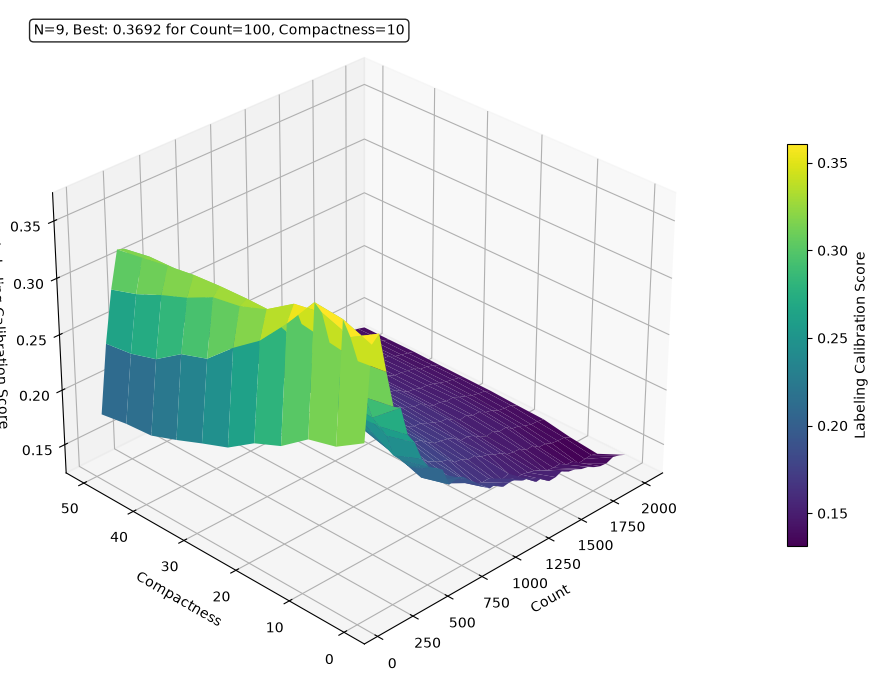

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read CSV with header
df = pd.read_csv(benchmark_csv_file, sep=delimiter)

# Select relevant columns by name
parsed = df[[special_parameter_1, special_parameter_2, quality_metric]].copy()
parsed = parsed.apply(pd.to_numeric, errors="coerce")

# Filter out rows where quality = 0
if ignore_sub_zero_quality_metric:
    parsed = parsed[parsed[quality_metric] > 0]

# Round Actual Superpixel Count to nearest 10 for better grouping
parsed[special_parameter_1] = (parsed[special_parameter_1] / 10).round() * 10

print(f"Total valid rows: {len(parsed)}")

# Average out the quality metric for each combination of parameters
parsed = parsed.groupby([special_parameter_1, special_parameter_2], as_index=False)[quality_metric].mean()

# Total number of different images
total_images = df["image_name"].nunique()
#print(f"Total number of different images: {total_images}")

# Build grid for surface plot
grid = parsed.pivot(index=special_parameter_2, columns=special_parameter_1, values=quality_metric)
x = grid.columns.to_numpy()
y = grid.index.to_numpy()
X, Y = np.meshgrid(x, y)
Z = grid.to_numpy()

# 2.5D surface plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")

ax.set_xlabel(special_parameter_1_title)
ax.set_ylabel(special_parameter_2_title)
ax.set_zlabel(quality_metric_title)
ax.view_init(elev=30, azim=225)
fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1, label=quality_metric_title)

max_row, max_col = np.unravel_index(np.nanargmax(Z), Z.shape)
ax.text2D(
    0.02, 0.98,
    f"N={total_images}, Best: {Z[max_row, max_col]:.4f} for {special_parameter_1_title}={x[max_col]:g}, {special_parameter_2_title}={y[max_row]:g}",
    transform=ax.transAxes,
    va="top",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85),
)

plt.tight_layout()
plt.savefig(f"{name}_{algorithm}_surface.pdf", format="pdf")
plt.show()






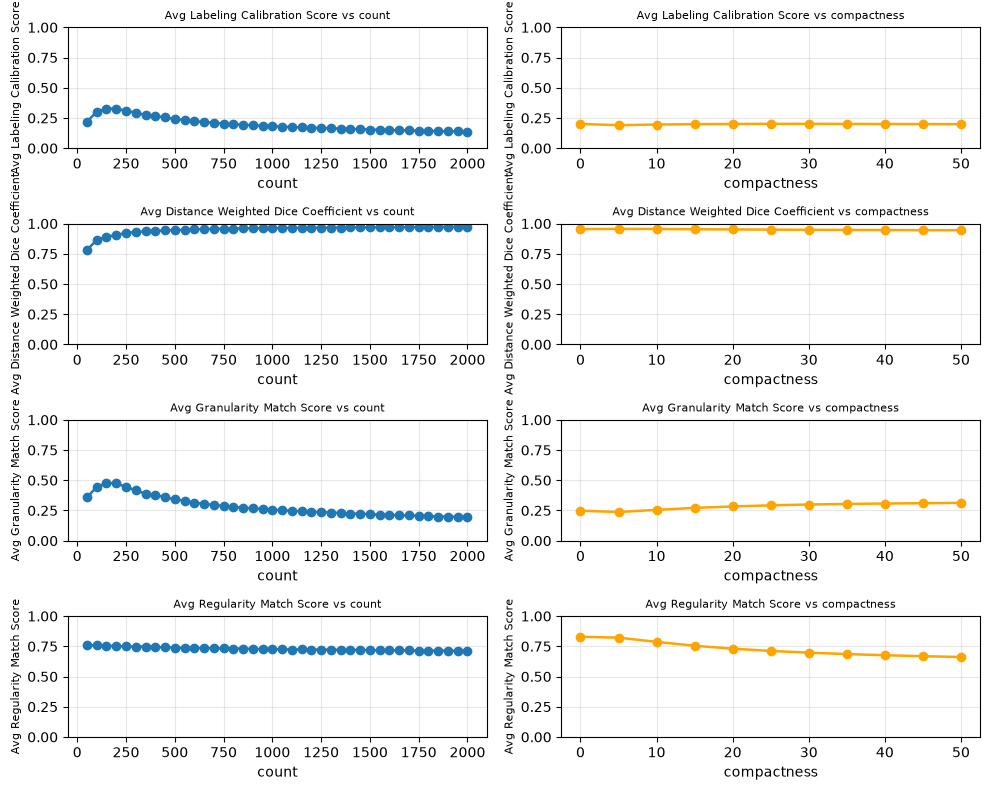

count = 150.0 gives highest labeling_calibration_score : 0.3275
compactness = 30 gives highest labeling_calibration_score : 0.2014


In [23]:
# Average quality metric over param2 for each param1 value
mean_by_param1 = grid.mean(axis=0)

# Average quality metric over param1 for each param2 value
mean_by_param2 = grid.mean(axis=1)

# Build sub-metric grids from parsed data (re-read with sub metrics)
full_sub = pd.read_csv(benchmark_csv_file, sep=delimiter)
full_sub = full_sub[[special_parameter_1, special_parameter_2, quality_metric, sub_metric_1, sub_metric_2, sub_metric_3, sub_metric_4, sub_metric_5]].copy()
full_sub = full_sub.apply(pd.to_numeric, errors="coerce")
if ignore_sub_zero_quality_metric:
	full_sub = full_sub[full_sub[quality_metric] > 0]
full_sub[special_parameter_1] = (full_sub[special_parameter_1] / 10).round() * 10
full_sub = full_sub.groupby([special_parameter_1, special_parameter_2], as_index=False)[[quality_metric, sub_metric_1, sub_metric_2, sub_metric_3, sub_metric_4, sub_metric_5]].mean()

def get_mean_series(metric):
	g = full_sub.pivot(index=special_parameter_2, columns=special_parameter_1, values=metric)
	return g.mean(axis=0), g.mean(axis=1)

fig_avg, axes = plt.subplots(4, 2, figsize=(10, 8))

metrics = [quality_metric, sub_metric_1, sub_metric_2, sub_metric_3]
metric_titles = [quality_metric_title, sub_metric_1_title, sub_metric_2_title, sub_metric_3_title]

for row, metric in enumerate(metrics):
	if metric == quality_metric:
		m_by_p1, m_by_p2 = mean_by_param1, mean_by_param2
	else:
		m_by_p1, m_by_p2 = get_mean_series(metric)

	axes[row, 0].plot(m_by_p1.index, m_by_p1.values, marker="o", linewidth=1.8)
	axes[row, 0].set_title(f"Avg {metric_titles[row]} vs {special_parameter_1}", fontsize=8)
	axes[row, 0].set_xlabel(special_parameter_1)
	axes[row, 0].set_ylabel(f"Avg {metric_titles[row]}", fontsize=8)
	axes[row, 0].set_ylim(0, 1)
	axes[row, 0].grid(alpha=0.3)

	axes[row, 1].plot(m_by_p2.index, m_by_p2.values, marker="o", linewidth=1.8, color="orange")
	axes[row, 1].set_title(f"Avg {metric_titles[row]} vs {special_parameter_2}", fontsize=8)
	axes[row, 1].set_xlabel(special_parameter_2)
	axes[row, 1].set_ylabel(f"Avg {metric_titles[row]}",fontsize=8)
	axes[row, 1].set_ylim(0, 1)
	axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{name}_{algorithm}_details.pdf",format="pdf")
plt.show()

max_quality_param1_index = mean_by_param1.abs().idxmax()
print(f"{special_parameter_1} = {max_quality_param1_index} gives highest {quality_metric} : {mean_by_param1[max_quality_param1_index]:.4f}")

max_quality_param2_index = mean_by_param2.abs().idxmax()
print(f"{special_parameter_2} = {max_quality_param2_index} gives highest {quality_metric} : {mean_by_param2[max_quality_param2_index]:.4f}")


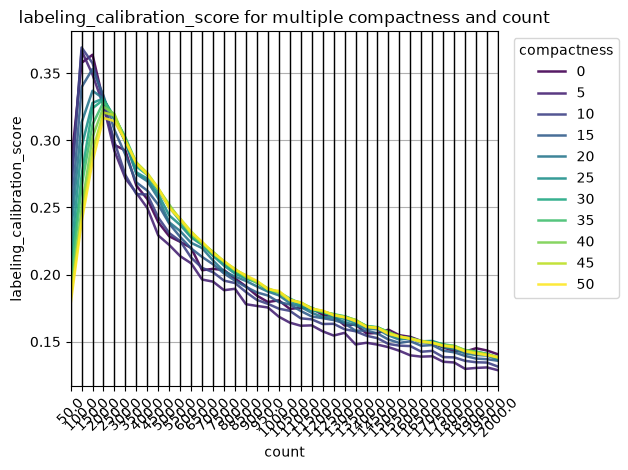

In [24]:
# Parallel coordinates view of the same quality metric surface data
pc_df = grid.reset_index().copy()
pc_df[special_parameter_2] = pc_df[special_parameter_2].astype(int).astype(str)

ax_pc = pd.plotting.parallel_coordinates(
	pc_df,
	class_column=special_parameter_2,
	colormap="viridis",
	linewidth=1.8,
	alpha=0.9
)

ax_pc.set_title(f"{quality_metric} for multiple {special_parameter_2} and {special_parameter_1}")
ax_pc.set_xlabel(special_parameter_1)
ax_pc.set_ylabel(quality_metric)
plt.xticks(rotation=45)
plt.legend(title=special_parameter_2, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


Number of images: 9
            count  compactness  labeling_calibration_score
count    9.000000     9.000000                    9.000000
mean   116.666667     8.333333                    0.390867
std     25.000000     6.123724                    0.156891
min    100.000000     0.000000                    0.122800
25%    100.000000     5.000000                    0.247500
50%    100.000000    10.000000                    0.498800
75%    150.000000    10.000000                    0.501200
max    150.000000    20.000000                    0.546800

Best count: mean=116.67, std=25.00
Best compactness: mean=8.33, std=6.12


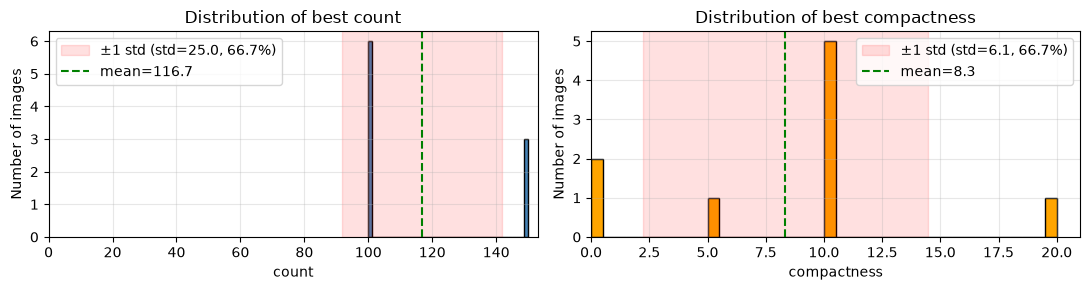


Images with lowest best count (100):
       image_name  count  compactness  labeling_calibration_score
CHNCXR_0114_0.png    100           10                      0.3798
CHNCXR_0335_1.png    100           10                      0.5059
CHNCXR_0396_1.png    100           20                      0.2147
CHNCXR_0456_1.png    100            5                      0.5012
CHNCXR_0524_1.png    100           10                      0.5003
CHNCXR_0568_1.png    100           10                      0.1228

Images with highest best count (150):
       image_name  count  compactness  labeling_calibration_score
CHNCXR_0011_0.png    150            0                      0.4988
CHNCXR_0398_1.png    150            0                      0.5468
CHNCXR_0602_1.png    150           10                      0.2475

Images with lowest best compactness (0):
       image_name  count  compactness  labeling_calibration_score
CHNCXR_0011_0.png    150            0                      0.4988
CHNCXR_0398_1.png    15

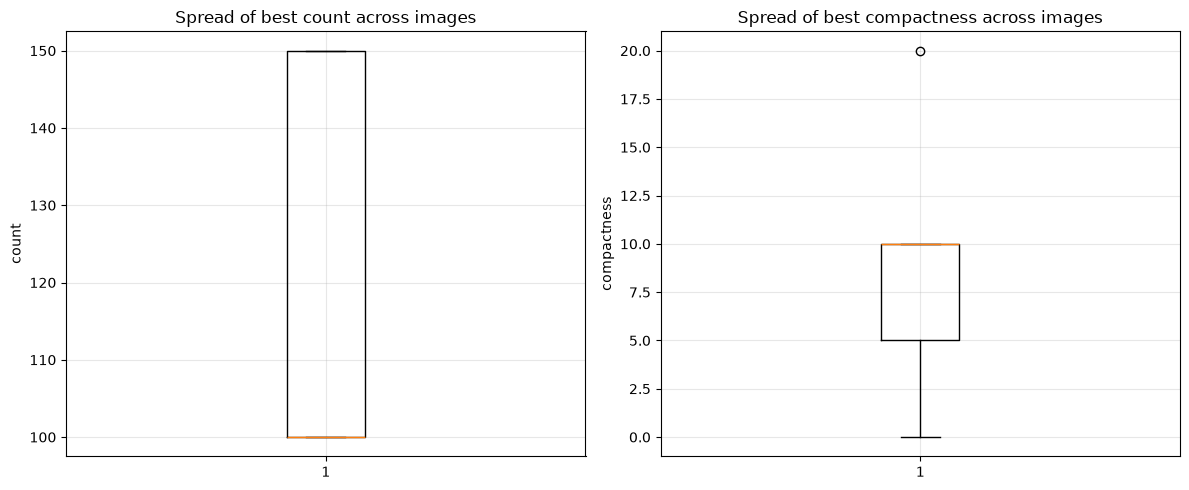

In [25]:
# For each image, find the parameter combination that yields the best quality metric
best_per_image = df.loc[df.groupby("image_name")[quality_metric].idxmax()][
    ["image_name", special_parameter_1, special_parameter_2, quality_metric]
].reset_index(drop=True)

print(f"Number of images: {len(best_per_image)}")
print(best_per_image.describe())

# Deviation (std) of the best parameters across images
std_param1 = best_per_image[special_parameter_1].std()
std_param2 = best_per_image[special_parameter_2].std()
mean_param1 = best_per_image[special_parameter_1].mean()
mean_param2 = best_per_image[special_parameter_2].mean()
median_param1 = best_per_image[special_parameter_1].median()
median_param2 = best_per_image[special_parameter_2].median()

print(f"\nBest {special_parameter_1}: mean={mean_param1:.2f}, std={std_param1:.2f}")
print(f"Best {special_parameter_2}: mean={mean_param2:.2f}, std={std_param2:.2f}")

# Visualize the spread of best parameters across images
fig_dev, axes_dev = plt.subplots(1, 2, figsize=(11, 3))

# Scatter of best param1 vs param2 per image
#axes_dev[0].scatter(
#    best_per_image[special_parameter_1],
#    best_per_image[special_parameter_2],
#    alpha=0.6,
#)
#axes_dev[0].set_xlabel(special_parameter_1)
#axes_dev[0].set_ylabel(special_parameter_2)
#axes_dev[0].set_title(f"Best ({special_parameter_1}, {special_parameter_2}) per image")
#axes_dev[0].set_xlim(left=0)
#axes_dev[0].set_ylim(bottom=0)
#axes_dev[0].grid(alpha=0.3)

# Histogram of best param1 across images
axes_dev[0].hist(best_per_image[special_parameter_1], bins=40, color="steelblue", edgecolor="black")
within_one_std = (
    best_per_image[special_parameter_1].between(
        mean_param1 - std_param1, mean_param1 + std_param1
    ).mean()
    * 100
)
axes_dev[0].axvspan(
    mean_param1 - std_param1,
    mean_param1 + std_param1,
    color="red",
    alpha=0.12,
    label=f"±1 std (std={std_param1:.1f}, {within_one_std:.1f}%)",
)
axes_dev[0].axvline(mean_param1, color="green", linestyle="--", label=f"mean={mean_param1:.1f}")
axes_dev[0].set_xlim(left=0)
axes_dev[0].set_xlabel(special_parameter_1)
axes_dev[0].set_ylabel("Number of images")
axes_dev[0].set_title(f"Distribution of best {special_parameter_1}")
axes_dev[0].legend()
axes_dev[0].grid(alpha=0.3)

# Histogram of best param2 across images
axes_dev[1].hist(best_per_image[special_parameter_2], bins=40, color="orange", edgecolor="black")
within_one_std = (
    best_per_image[special_parameter_2].between(
        mean_param2 - std_param2, mean_param2 + std_param2
    ).mean()
    * 100
)
axes_dev[1].axvspan(
    mean_param2 - std_param2,
    mean_param2 + std_param2,
    color="red",
    alpha=0.12,
    label=f"±1 std (std={std_param2:.1f}, {within_one_std:.1f}%)",
)
axes_dev[1].axvline(mean_param2, color="green", linestyle="--", label=f"mean={mean_param2:.1f}")
axes_dev[1].set_xlabel(special_parameter_2)
axes_dev[1].set_xlim(left=0)
axes_dev[1].set_ylabel("Number of images")
axes_dev[1].set_title(f"Distribution of best {special_parameter_2}")
axes_dev[1].legend()
axes_dev[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{name}_{algorithm}_distribution.pdf", format="pdf")
plt.show()

# Boxplots to visualize spread more explicitly
fig_box, axes_box = plt.subplots(1, 2, figsize=(12, 5))
axes_box[0].boxplot(best_per_image[special_parameter_1], orientation="vertical")
axes_box[0].set_title(f"Spread of best {special_parameter_1} across images")
axes_box[0].set_ylabel(special_parameter_1)
axes_box[0].grid(alpha=0.3)

axes_box[1].boxplot(best_per_image[special_parameter_2], orientation="vertical")
axes_box[1].set_title(f"Spread of best {special_parameter_2} across images")
axes_box[1].set_ylabel(special_parameter_2)
axes_box[1].grid(alpha=0.3)

# Images whose best result uses the lowest or highest value of each parameter
for parameter in [special_parameter_1, special_parameter_2]:
    lowest_value = best_per_image[parameter].min()
    highest_value = best_per_image[parameter].max()

    print(f"\nImages with lowest best {parameter} ({lowest_value}):")
    print(
        best_per_image.loc[
            best_per_image[parameter] == lowest_value,
            ["image_name", special_parameter_1, special_parameter_2, quality_metric],
        ].to_string(index=False)
    )

    print(f"\nImages with highest best {parameter} ({highest_value}):")
    print(
        best_per_image.loc[
            best_per_image[parameter] == highest_value,
            ["image_name", special_parameter_1, special_parameter_2, quality_metric],
        ].to_string(index=False)
    )

plt.tight_layout()
plt.show()